# Examenes SAT
## P1: Limpieza de datos con Python y Pandas

# 1. El problema del negocio

Cada año, los estudiantes de secundaria en Estados Unidos participan en los exámenes SAT, que funcionan como evaluaciones estandarizadas diseñadas para medir sus competencias en lectura, matemáticas y escritura. Estos exámenes se componen de secciones de lectura, matemáticas y escritura, cada una con una puntuación máxima de 800 puntos, y tienen un peso significativo tanto para los estudiantes como para las universidades, influyendo profundamente en el proceso de admisión.

Con base a esto podemos realizar:

¿Cuáles son las 20 escuelas con los mejores promedios combinados en matemáticas, lectura y escritura del SAT, y cómo se distribuyen estos colegios de élite académica entre los diferentes boroughs de Nueva York (Manhattan, Bronx, Brooklyn, Queens, Staten Island)?

#2. El set de datos

La información recolectada se encuentra en un archivo CSV (`SchoolTransport.csv`) con 375 filas y 7 columnas.

En el cual podemos encontrar:

**school_name**	= Nombre de la escuela.

**borough**	= Distrito o borough de la ciudad de Nueva York (ej. Manhattan, Bronx, etc.).

**building_code**	= Código de identificación del edificio escolar.

**average_math** = Puntaje promedio en la sección de matemáticas del SAT.

**average_reading**	= Puntaje promedio en la sección de lectura del SAT.

**average_writing** = Puntaje promedio en la sección de escritura del SAT.

**percent_tested** = Porcentaje de estudiantes de la escuela que presentaron el examen SAT.

#3. Una primera mirada al dataset

In [ ]:
# Importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Lectura
from google.colab import drive
drive.mount('/gdrive')

ruta = "/gdrive/MyDrive/Datos/SchoolTransport.csv"
data = pd.read_csv(ruta)

Mounted at /gdrive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
print(data.shape)
data.head()

(375, 7)


,school_name,borough,building_code,average_math,average_reading,average_writing,percent_tested
0,"New Explorations into Science, Technology and ...",Manhattan,M022,657,601,601,NaN
1,Essex Street Academy,Manhattan,M445,395,411,387,78.9
2,Lower Manhattan Arts Academy,Manhattan,M445,418,428,415,65.1
3,High School for Dual Language and Asian Studies,Manhattan,M445,613,453,463,95.9
4,Henry Street School for International Studies,Manhattan,M056,410,406,381,59.7


In [ ]:
# Veamos las variables categóricas y las numéricas
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375 entries, 0 to 374
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   school_name      375 non-null    object 
 1   borough          375 non-null    object 
 2   building_code    375 non-null    object 
 3   average_math     375 non-null    int64  
 4   average_reading  375 non-null    int64  
 5   average_writing  375 non-null    int64  
 6   percent_tested   355 non-null    float64
dtypes: float64(1), int64(3), object(3)
memory usage: 20.6+ KB


#4. Limpieza

Realizaremos el proceso de limpieza teniendo en cuenta las situaciones más comunes:

1. Datos faltantes en algunas celdas
2. Columnas irrelevantes (que no responden al problema que queremos resolver)
3. Registros (filas) repetidos
4. Valores extremos (*outliers*) en el caso de las variables numéricas. Se deben analizar en detalle pues no necesariamente la solución es eliminarlos
5. Errores tipográficos en el caso de las variables categóricas

Al final de este proceso de limpieza deberíamos tener un set de datos **íntegro**, listo para la fase de Análisis Exploratorio.

## 4.1 Datos faltantes

Acá comenzamos a ver que los datos no están completos, pues no todas las columnas tienen la misma cantidad de registros.

El número total de registros deberia ser 355.

Por ser tan pocos los datos  faltantes optaremos por eliminar las filas correspondientes:

In [ ]:
data.dropna(inplace=True)
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 355 entries, 1 to 374
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   school_name      355 non-null    object 
 1   borough          355 non-null    object 
 2   building_code    355 non-null    object 
 3   average_math     355 non-null    int64  
 4   average_reading  355 non-null    int64  
 5   average_writing  355 non-null    int64  
 6   percent_tested   355 non-null    float64
dtypes: float64(1), int64(3), object(3)
memory usage: 22.2+ KB


##4.2 Columnas irrelevantes

Una columna irrelevante puede ser:

- **Una columna que no contiene información relevante para el problema que queremos resolver**. Por ejemplo en este caso podría ser una columna que no guarde relación con el posible perfil del cliente (deporte favorito, hobbies, comida favorita, etc.)
- **Una columna categórica pero con un sólo nivel**. Por ejemplo si en la columna "job" solo tuviésemos el nivel "unknown".
- **Una columna numérica pero con un sólo valor**. Por ejemplo si en la columna "edad" todos los vlaores fuesen iguales a 50.
- **Columnas con información redundante**. Por ejemplo si además de las columnas "month" y "day" tuviésemos la columna "month-day", resultado de combinar las dos anteriores.

Si tenemos la duda de si alguna columna puede ser relevante o no lo mejor es dejarla (y más adelante en posteriores etapas podremos darnos cuenta de si se debe preservar o no).

En este caso todas las columnas pueden resultar relevantes, pero debemos verificar que no haya columnas categóricas con un sólo nivel, o columnas numéricas con un sólo valor:

In [ ]:
# Conteo de los niveles en las diferentes columnas categóricas
cols_cat = ['school_name', 'borough', 'building_code']

for col in cols_cat:
  print(f'Columna {col}: {data[col].nunique()} subniveles')

Columna school_name: 355 subniveles
Columna borough: 5 subniveles
Columna building_code: 223 subniveles


Todas las columnas categóricas tienen más de 1 subnivel. No eliminaremos ninguna.

Verifiquemos lo que ocurre con las columnas numéricas:

In [ ]:
data.describe()

,average_math,average_reading,average_writing,percent_tested
count,355.000000,355.000000,355.000000,355.000000
mean,433.335211,425.061972,419.028169,64.976338
std,72.180273,61.903256,64.444469,18.747634
min,317.000000,302.000000,292.000000,18.500000
25%,386.000000,386.000000,382.000000,50.950000
50%,415.000000,413.000000,402.000000,64.800000
75%,459.500000,445.000000,439.000000,79.600000
max,754.000000,697.000000,693.000000,100.000000


Todas las columnas numéricas tienen desviaciones estándar ("std") diferentes de cero, lo que indica que no tienen un único valor.

Preservaremos todas las columnas numéricas.

##4.3 Filas repetidas

In [ ]:
print(f'Tamaño del set antes de eliminar las filas repetidas: {data.shape}')
data.drop_duplicates(inplace=True)
print(f'Tamaño del set después de eliminar las filas repetidas: {data.shape}')

Tamaño del set antes de eliminar las filas repetidas: (355, 7)
Tamaño del set después de eliminar las filas repetidas: (355, 7)


##4.4 *Outliers* en las variables numéricas

No siempre se deben eliminar los *outliers* porque dependiendo de la variable numérica analizada estos pueden contener información importante.

Creemos gráficas tipo "boxplot" de las columnas numéricas:

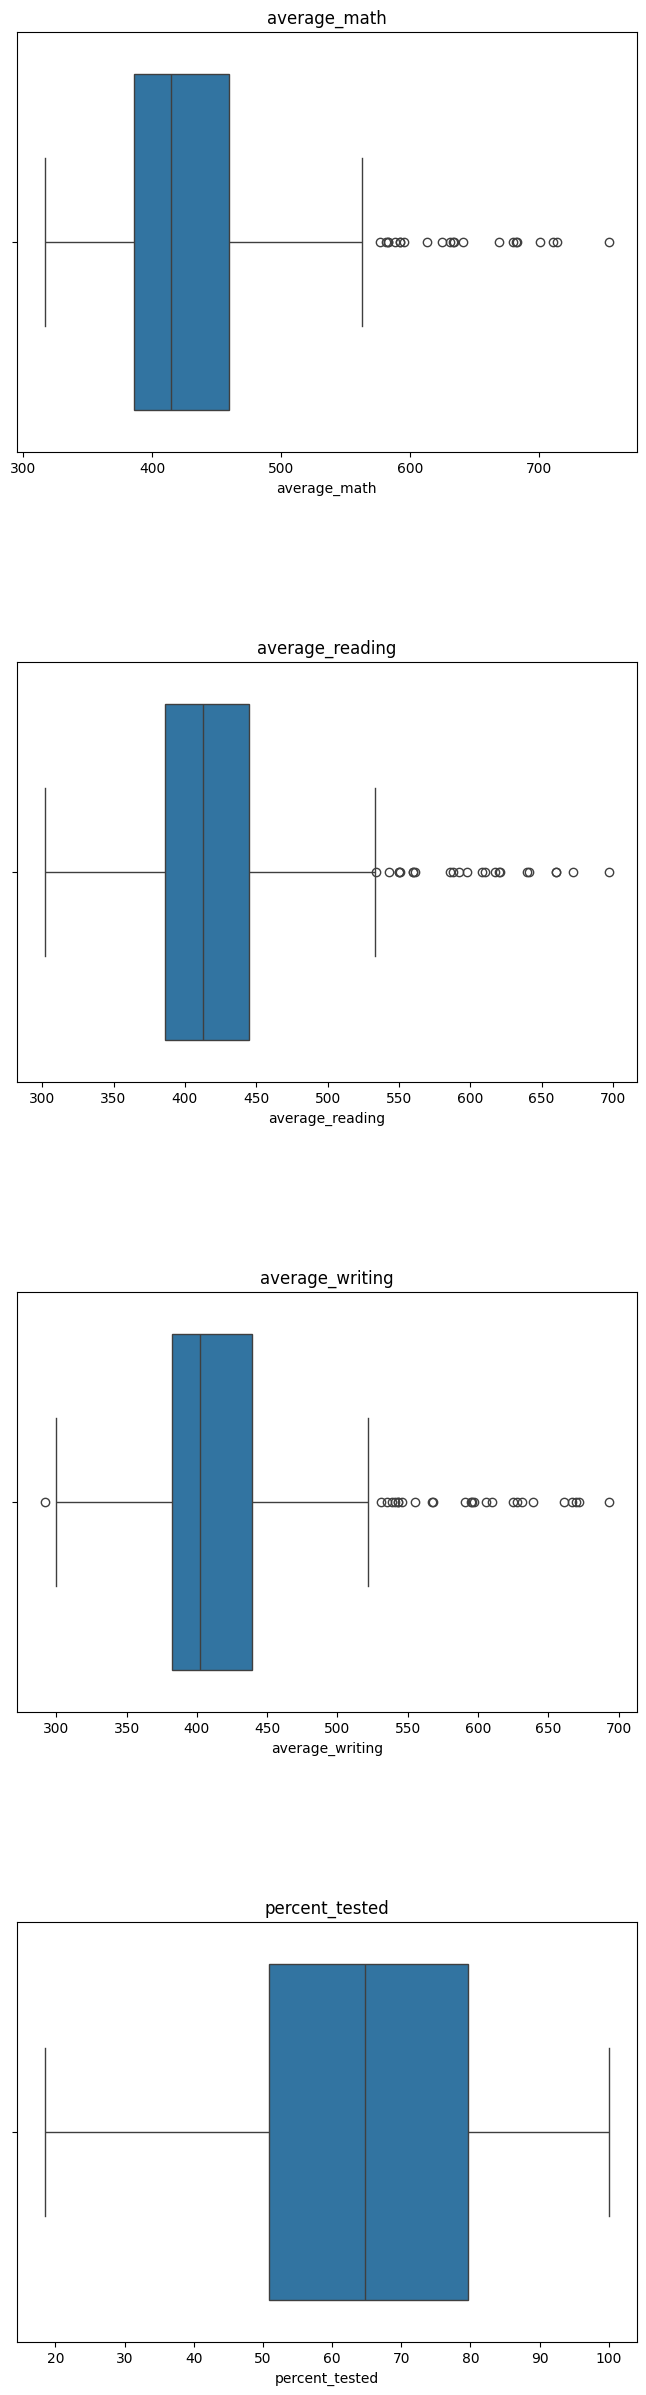

In [ ]:
# Generar gráficas individuales pues las variables numéricas
# están en rangos diferentes
cols_num = ['average_math',
            'average_reading',
            'average_writing',
            'percent_tested']

fig, ax = plt.subplots(nrows=4, ncols=1, figsize=(8,30))
fig.subplots_adjust(hspace=0.5)

for i, col in enumerate(cols_num):
    sns.boxplot(x=col, data=data, ax=ax[i])
    ax[i].set_title(col)

**Observaciones:**

**"average_math":** muestra que la mayoría de las escuelas se concentran entre 380 y 480 puntos, mientras que existen varios outliers hacia arriba (algunas escuelas con puntajes superiores a 600–700) que destacan por un rendimiento muy por encima del promedio. Esto indica una fuerte variabilidad en el desempeño matemático entre escuelas, con pocas instituciones alcanzando resultados excepcionales.

**"average_reading":** La mayoría de las escuelas tienen puntajes entre 390 y 470, con algunos outliers hacia arriba (más de 600), lo que refleja que solo unas pocas instituciones logran un rendimiento sobresaliente en lectura.

**"average_writing":** Los puntajes típicos se concentran entre 390 y 460, pero aparecen muchos outliers altos (más de 550 hasta casi 700), mostrando que la escritura tiene mayor dispersión que la lectura y que ciertas escuelas alcanzan resultados excepcionales.

**"percent_tested":** La mediana está cerca de 65%, con la mayoría de escuelas entre 50% y 80% de estudiantes evaluados. No se observan valores extremos importantes, lo que indica que la participación en el SAT es relativamente uniforme entre escuelas.

In [ ]:
# Eliminar filas con "average_math">800
print(f'Tamaño del set antes de eliminar registros de edad: {data.shape}')
data = data[data['average_math']<=800]
print(f'Tamaño del set después de eliminar registros de edad: {data.shape}')

Tamaño del set antes de eliminar registros de edad: (355, 7)
Tamaño del set después de eliminar registros de edad: (355, 7)


In [ ]:
# Eliminar filas con "average_reading">800
print(f'Tamaño del set antes de eliminar registros de duración: {data.shape}')
data = data[data['average_reading']<=800]
print(f'Tamaño del set después de eliminar registros de duración: {data.shape}')

Tamaño del set antes de eliminar registros de duración: (355, 7)
Tamaño del set después de eliminar registros de duración: (355, 7)


In [ ]:
# Eliminar filas con "previous">800
print(f'Tamaño del set antes de eliminar registros de previous: {data.shape}')
data = data[data['average_reading']<=800]
print(f'Tamaño del set después de eliminar registros de previous: {data.shape}')

Tamaño del set antes de eliminar registros de previous: (355, 7)
Tamaño del set después de eliminar registros de previous: (355, 7)


**Observaciones:**

En este caso no se recomienda eliminar los datos con valores atípicos, ya que estos pueden representar escuelas o estudiantes con rendimientos excepcionalmente altos en lectura, escritura o matemáticas. Lejos de ser errores, estos valores reflejan la diversidad real del desempeño académico y pueden aportar información clave para identificar instituciones destacadas o con necesidades de apoyo. Por ello, es preferible analizarlos y contextualizarlos en lugar de descartarlos, pues eliminarlos implicaría perder patrones valiosos para la toma de decisiones educativas.

##4.5 Errores tipográficos en variables categóricas


En el contexto de nuestra base de datos (SchoolTransport), este problema no se presenta, ya que los nombres de las escuelas, códigos de edificio y distritos fueron revisados y no existen variaciones tipográficas ni diferencias por mayúsculas o minúsculas que generen categorías duplicadas. Esto garantiza que cada valor categórico esté correctamente representado sin necesidad de ajustes adicionales.

Sin embargo, se realiza la practica para tambien descartar posibles duplicados.

/tmp/ipython-input-764858320.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=45, ha='right')
/tmp/ipython-input-764858320.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=45, ha='right')
/tmp/ipython-input-764858320.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=45, ha='right')


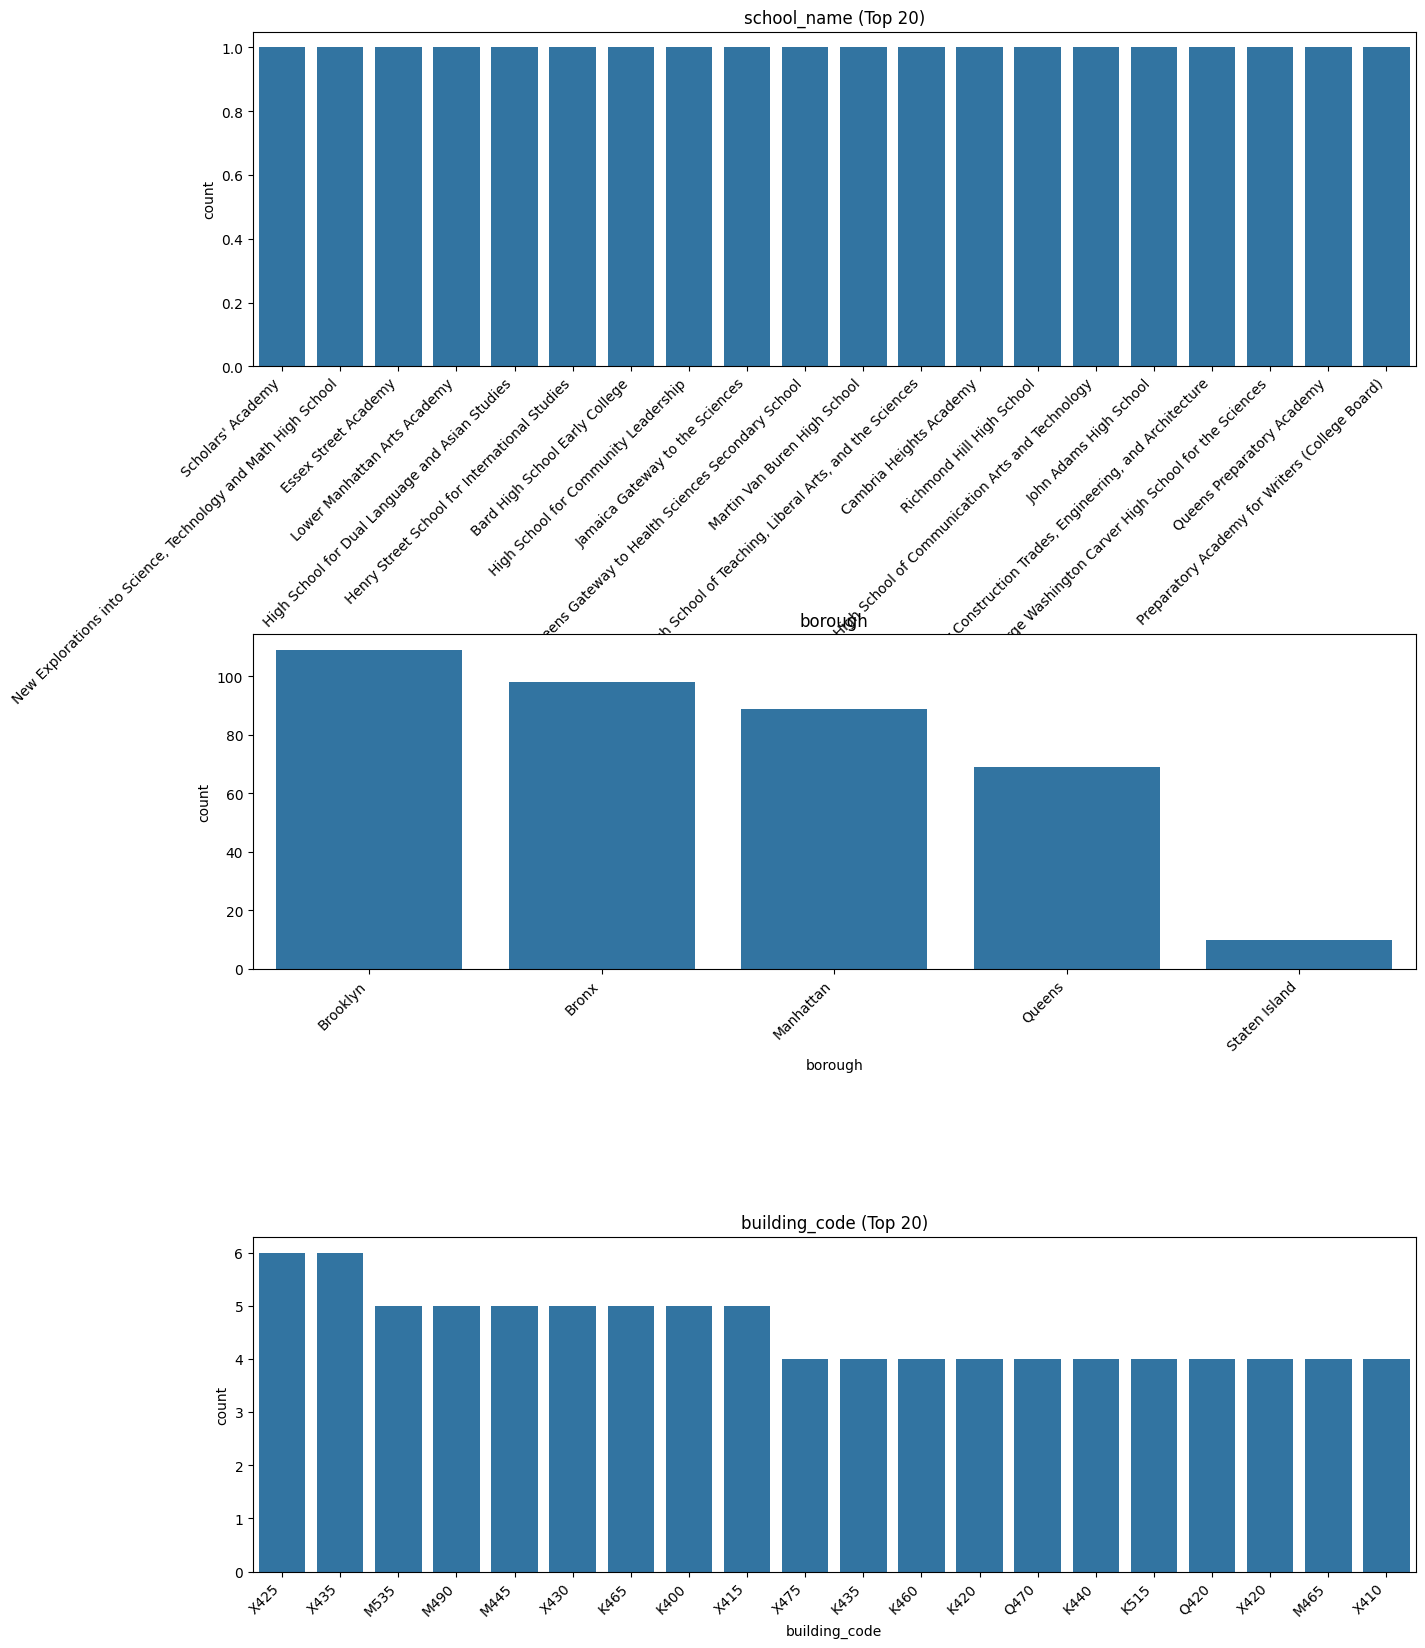

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Variables categóricas
cols_cat = ['school_name', 'borough', 'building_code']

fig, ax = plt.subplots(nrows=3, ncols=1, figsize=(15, 20))
fig.subplots_adjust(hspace=0.8)

for i, col in enumerate(cols_cat):
    # Si la columna tiene demasiados niveles, graficar solo el Top 20
    if data[col].nunique() > 20:
        top_vals = data[col].value_counts().nlargest(20).index
        sns.countplot(x=col, data=data[data[col].isin(top_vals)], ax=ax[i], order=top_vals)
        ax[i].set_title(f"{col} (Top 20)")
    else:
        sns.countplot(x=col, data=data, ax=ax[i], order=data[col].value_counts().index)
        ax[i].set_title(col)

    ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=45, ha='right')

plt.show()





Dado que las variables categóricas como school_name y building_code contienen una gran cantidad de categorías únicas, graficarlas en su totalidad generaba visualizaciones demasiado extensas y difíciles de interpretar. Por este motivo, se decidió mostrar únicamente las 20 categorías más frecuentes (Top 20), lo que permite una representación más clara y enfocada de la distribución de los datos.

/tmp/ipython-input-129945909.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=90, ha='center')
/tmp/ipython-input-129945909.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=90, ha='center')
/tmp/ipython-input-129945909.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=90, ha='center')


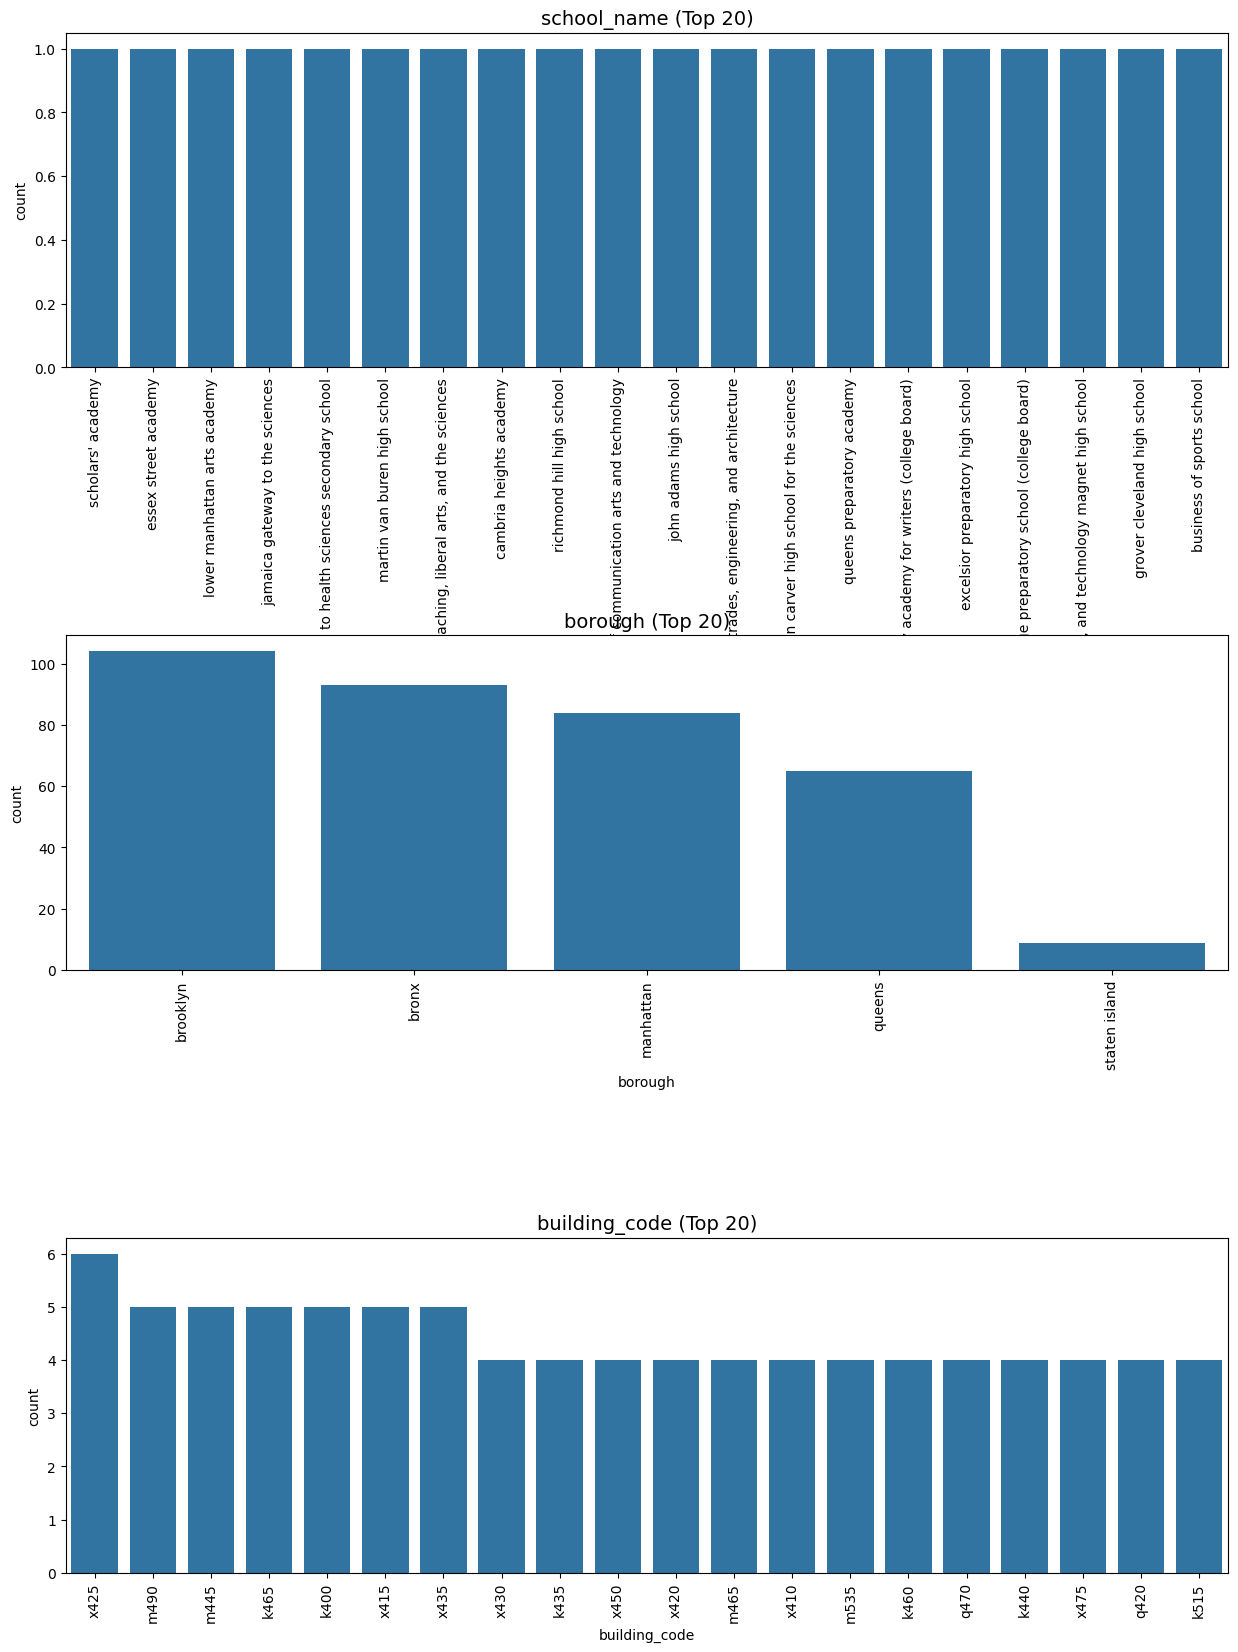

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pasar a minúsculas las columnas categóricas
for column in cols_cat:
    data[column] = data[column].str.lower()

# Crear figura con tantas filas como columnas categóricas
fig, ax = plt.subplots(nrows=len(cols_cat), ncols=1, figsize=(15, 20))
fig.subplots_adjust(hspace=0.8)

# Graficar cada categórica con Top 20
for i, col in enumerate(cols_cat):
    top_vals = data[col].value_counts().nlargest(20).index
    sns.countplot(x=col, data=data[data[col].isin(top_vals)], ax=ax[i], order=top_vals)
    ax[i].set_title(f"{col} (Top 20)", fontsize=14)
    ax[i].set_xticklabels(ax[i].get_xticklabels(), rotation=90, ha='center')

plt.show()



En la revisión de la base de datos se comprobó que los nombres de colegios en la columna school_name y building_code no presentan repeticiones, incluso tras normalizarlos a minúsculas para evitar diferencias por el uso de mayúsculas o minúsculas. Esto significa que cada institución educativa en el dataset está identificada de manera única y no existen registros duplicados en cuanto a nombres de escuelas.

In [ ]:
data.shape

(355, 7)

Con la respectiva limpieza de datos:

Originalmente teniamos 375 registros y 7 columnas. El dataset resultante tiene 355 filas (20 registros menos) y 7 columnas.

El set de datos ya está listo para el Análisis Exploratorio.

In [ ]:
from google.colab import files

# Exportar y descargar
data.to_csv("SchoolTransport_clean.csv", index=False)
files.download("SchoolTransport_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>